**Cognitive Computing Assignment 10**

Name - Kushal Roll no. - 1024160003

In [12]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

Labelled corpus

In [13]:
corpus = {
    "symptoms": [
        "What are the common symptoms of diabetes?",
        "Why do I feel very thirsty all the time?",
        "I am urinating frequently at night, is it diabetes?",
        "What are the early signs of high blood sugar?",
        "Can blurred vision be a sign of diabetes?",
        "Why do my wounds heal slowly?",
        "I feel tired and lose weight without trying, what could it be?",
        "How do I know if I have diabetes?",
        "Is excessive hunger a symptom of diabetes?",
        "Do frequent infections indicate diabetes?",
        "Why am I always hungry and thirsty?",
        "What are the signs and symptoms of type 2 diabetes?",
        "Does sudden weight loss mean I have diabetes?",
        "Is dry mouth a sign of high blood sugar?",
        "What are the symptoms of type 1 diabetes in children?",
        "How can I tell if my sugar is high from how I feel?",
    ],
    "diet": [
        "What foods should a diabetic eat?",
        "Which foods should I avoid with diabetes?",
        "Can diabetic patients eat rice?",
        "Is sugar completely forbidden for diabetics?",
        "What is a good breakfast for a diabetic person?",
        "How many carbohydrates should I eat in a meal?",
        "Are fruits safe for people with diabetes?",
        "Can I drink fruit juice if I have diabetes?",
        "What should I eat for dinner if I have high sugar?",
        "Can diabetics eat sweets or chocolate?",
        "Give me a healthy diet chart for diabetes.",
        "Is bread or milk allowed in a diabetic diet?",
        "Is jaggery or honey better than sugar for diabetics?",
        "How much roti should a diabetic eat?",
        "What snacks are good for diabetes?",
        "Which vegetables are best for a diabetic diet?",
        "What should I eat for lunch if my sugar is high?",
        "Tell me what to eat and what to avoid.",
    ],
    "medication": [
        "How does metformin work?",
        "When should I take my insulin?",
        "What are the side effects of diabetes medicines?",
        "Can I stop my diabetes tablets if my sugar is normal?",
        "What is the difference between type 1 and type 2 treatment?",
        "Do I need insulin injections for diabetes?",
        "What happens if I miss a dose of my medicine?",
        "Is metformin safe for long-term use?",
        "How should I store my insulin pen?",
        "Can I take diabetes medicine on an empty stomach?",
        "What are the types of insulin?",
        "Which tablets are prescribed for type 2 diabetes?",
        "Does insulin cause weight gain?",
        "Can diabetes medicine damage my liver?",
        "How do insulin injections work?",
        "What should I do if my diabetes tablets are not working?",
    ],
    "monitoring": [
        "What should my fasting blood sugar level be?",
        "How often should I check my blood glucose?",
        "What is an HbA1c test?",
        "What is a normal blood sugar reading after meals?",
        "How do I use a glucometer?",
        "What HbA1c value indicates diabetes?",
        "When is the best time to test my sugar?",
        "What is a good target for my blood sugar?",
        "How do I read my glucose meter results?",
        "Should I check my sugar every day?",
        "What is the normal range for HbA1c?",
        "What does a random blood sugar test show?",
        "How do I prepare for a fasting blood sugar test?",
        "What is a normal HbA1c for a diabetic?",
        "How accurate are home glucose meters?",
        "What is postprandial blood sugar?",
    ],
    "complications": [
        "What are the long-term complications of diabetes?",
        "Can diabetes damage my kidneys?",
        "How does diabetes affect the eyes?",
        "Why do diabetics get foot ulcers?",
        "Can diabetes cause nerve damage?",
        "Does diabetes increase the risk of heart disease?",
        "How can I prevent diabetic complications?",
        "What is diabetic neuropathy?",
        "Can high sugar cause blindness?",
        "Can uncontrolled sugar lead to kidney failure?",
        "Why do diabetics lose sensation in their feet?",
        "What is diabetic retinopathy?",
        "Can diabetes cause amputation?",
        "What is diabetic nephropathy?",
        "How does diabetes harm blood vessels?",
        "Why should diabetics get yearly eye and kidney tests?",
    ],
    "lifestyle": [
        "How much exercise should a diabetic do?",
        "Is walking good for controlling blood sugar?",
        "Can yoga help manage diabetes?",
        "Can I lose weight to reverse diabetes?",
        "How does stress affect my blood sugar?",
        "Does lack of sleep affect diabetes?",
        "Should I check sugar before exercising?",
        "Can smoking make diabetes worse?",
        "Which exercises are best for diabetes?",
        "Can I go to the gym if I have diabetes?",
        "Does drinking alcohol affect diabetes?",
        "How can I manage my weight with diabetes?",
        "Is it good to walk after dinner with diabetes?",
        "Can meditation lower my sugar?",
        "How many hours should I sleep to control diabetes?",
        "Does being overweight increase my diabetes risk?",
    ],
}

rows = [(q, intent) for intent, qs in corpus.items() for q in qs]
df = pd.DataFrame(rows, columns=["query", "intent"])
print("Total queries:", len(df), "| Intents:", df["intent"].nunique())
print(df["intent"].value_counts())

Total queries: 98 | Intents: 6
intent
diet             18
symptoms         16
medication       16
monitoring       16
complications    16
lifestyle        16
Name: count, dtype: int64


Hierarchical taxonomy

In [14]:
taxonomy = {
    "Diagnosis & Monitoring": {
        "Symptoms & Warning Signs": {
            "intent": "symptoms",
            "topics": ["thirst", "urination", "blurred vision", "tired", "weight loss", "wound", "hungry"]},
        "Blood Glucose Testing": {
            "intent": "monitoring",
            "topics": ["fasting", "hba1c", "glucometer", "glucose", "target", "test", "reading"]},
    },
    "Treatment": {
        "Oral Medication": {
            "intent": "medication",
            "topics": ["metformin", "tablet", "side effect", "long-term", "medicine"]},
        "Insulin Therapy": {
            "intent": "medication",
            "topics": ["insulin", "injection", "pen", "missed", "dose"]},
    },
    "Lifestyle Management": {
        "Nutrition & Diet": {
            "intent": "diet",
            "topics": ["food", "eat", "carbohydrate", "fruit", "rice", "meal", "diet"]},
        "Physical Activity & Habits": {
            "intent": "lifestyle",
            "topics": ["exercise", "walk", "yoga", "sleep", "stress", "smoking", "weight"]},
    },
    "Complications & Prevention": {
        "Eye, Kidney & Nerve Damage": {
            "intent": "complications",
            "topics": ["eye", "retinopathy", "kidney", "nephropathy", "neuropathy", "nerve", "blindness"]},
        "Heart, Foot & Vessel Care": {
            "intent": "complications",
            "topics": ["heart", "foot", "feet", "ulcer", "vessel", "stroke", "prevent"]},
    },
}

intent_path = {}
for category, subs in taxonomy.items():
    for sub, info in subs.items():
        intent_path.setdefault(info["intent"], f"{category} > {sub}")


def locate(intent, query):
    q = query.lower()
    best, best_hits = intent_path[intent], 0
    for category, subs in taxonomy.items():
        for sub, info in subs.items():
            if info["intent"] != intent:
                continue
            hits = sum(t in q for t in info["topics"])
            if hits > best_hits:
                best, best_hits = f"{category} > {sub}", hits
    return best


for category, subs in taxonomy.items():
    print(category)
    for sub, info in subs.items():
        print("   -", sub, "| intent:", info["intent"], "| topics:", info["topics"])


Diagnosis & Monitoring
   - Symptoms & Warning Signs | intent: symptoms | topics: ['thirst', 'urination', 'blurred vision', 'tired', 'weight loss', 'wound', 'hungry']
   - Blood Glucose Testing | intent: monitoring | topics: ['fasting', 'hba1c', 'glucometer', 'glucose', 'target', 'test', 'reading']
Treatment
   - Oral Medication | intent: medication | topics: ['metformin', 'tablet', 'side effect', 'long-term', 'medicine']
   - Insulin Therapy | intent: medication | topics: ['insulin', 'injection', 'pen', 'missed', 'dose']
Lifestyle Management
   - Nutrition & Diet | intent: diet | topics: ['food', 'eat', 'carbohydrate', 'fruit', 'rice', 'meal', 'diet']
   - Physical Activity & Habits | intent: lifestyle | topics: ['exercise', 'walk', 'yoga', 'sleep', 'stress', 'smoking', 'weight']
Complications & Prevention
   - Eye, Kidney & Nerve Damage | intent: complications | topics: ['eye', 'retinopathy', 'kidney', 'nephropathy', 'neuropathy', 'nerve', 'blindness']
   - Heart, Foot & Vessel Care 

Ontology

In [15]:
relationships = [
    ("Patient", "has", "Diabetes"),
    ("Diabetes", "causes", "High Blood Glucose"),
    ("Insulin", "lowers", "Blood Glucose"),
    ("Metformin", "treats", "Type 2 Diabetes"),
    ("HbA1c", "measures", "Average Blood Glucose"),
    ("Glucometer", "measures", "Blood Glucose"),
    ("Healthy Diet", "controls", "Blood Glucose"),
    ("Exercise", "improves", "Insulin Sensitivity"),
    ("Uncontrolled Diabetes", "leads to", "Complications"),
    ("Complications", "include", "Retinopathy"),
    ("Complications", "include", "Nephropathy"),
    ("Complications", "include", "Neuropathy"),
    ("Excess Insulin", "causes", "Hypoglycemia"),
    ("Hypoglycemia", "requires", "Fast-acting Carbohydrate"),
]

concepts = sorted({s for s, _, _ in relationships} | {o for _, _, o in relationships})
print("Concepts:", len(concepts))
print("Relationships:", len(relationships))
for s, r, o in relationships:
    print(f"{s} --{r}--> {o}")


def related(concept):
    return [(s, r, o) for s, r, o in relationships if concept.lower() in (s.lower(), o.lower())]

Concepts: 21
Relationships: 14
Patient --has--> Diabetes
Diabetes --causes--> High Blood Glucose
Insulin --lowers--> Blood Glucose
Metformin --treats--> Type 2 Diabetes
HbA1c --measures--> Average Blood Glucose
Glucometer --measures--> Blood Glucose
Healthy Diet --controls--> Blood Glucose
Exercise --improves--> Insulin Sensitivity
Uncontrolled Diabetes --leads to--> Complications
Complications --include--> Retinopathy
Complications --include--> Nephropathy
Complications --include--> Neuropathy
Excess Insulin --causes--> Hypoglycemia
Hypoglycemia --requires--> Fast-acting Carbohydrate


NLP preprocessing

In [16]:
tokenizer = RegexpTokenizer(r"[a-z0-9]+")
stop_words = set(stopwords.words("english")) - {"no", "not"}
lemmatizer = WordNetLemmatizer()


def lemmatize_word(token):
    base = lemmatizer.lemmatize(token, "n")
    if base.endswith("ing") or base.endswith("ed"):
        base = lemmatizer.lemmatize(base, "v")
    return base


def preprocess(text):
    text = text.lower()
    tokens = tokenizer.tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatize_word(t) for t in tokens]
    return " ".join(tokens)


df["clean"] = df["query"].apply(preprocess)
print(df[["query", "clean"]].head(8).to_string(index=False))

                                                         query                                   clean
                     What are the common symptoms of diabetes?                 common symptom diabetes
                      Why do I feel very thirsty all the time?                       feel thirsty time
           I am urinating frequently at night, is it diabetes?       urinate frequently night diabetes
                 What are the early signs of high blood sugar?             early sign high blood sugar
                     Can blurred vision be a sign of diabetes?               blur vision sign diabetes
                                 Why do my wounds heal slowly?                       wound heal slowly
I feel tired and lose weight without trying, what could it be? feel tire lose weight without try could
                             How do I know if I have diabetes?                           know diabetes


TF-IDF and Logistic Regression

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=42)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("clf", LogisticRegression(C=100, max_iter=2000)),
])
model.fit(X_train, y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('clf', LogisticRegression(C=100, max_iter=2000))])

Evaluation

Accuracy : 0.800
Precision: 0.835
Recall   : 0.800
F1-score : 0.794

               precision    recall  f1-score   support

complications       0.67      1.00      0.80         4
         diet       1.00      1.00      1.00         5
    lifestyle       0.50      0.50      0.50         4
   medication       1.00      0.75      0.86         4
   monitoring       0.80      1.00      0.89         4
     symptoms       1.00      0.50      0.67         4

     accuracy                           0.80        25
    macro avg       0.83      0.79      0.79        25
 weighted avg       0.83      0.80      0.79        25

4-fold cross-validation accuracy: [0.92  0.68  0.625 0.667] mean = 0.723


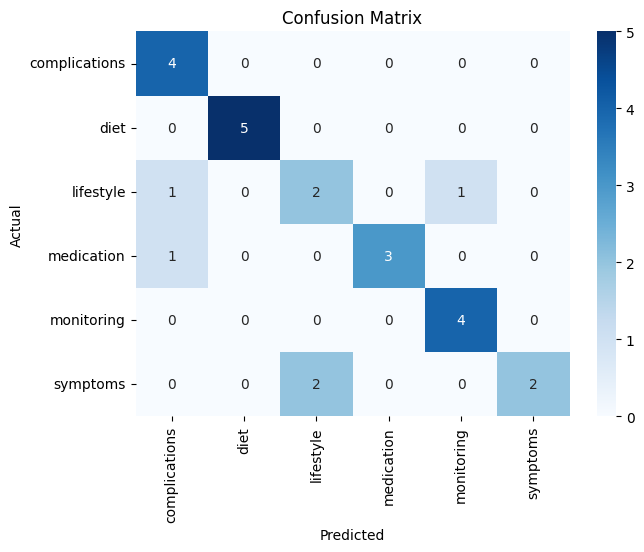

Pipeline(steps=[('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('clf', LogisticRegression(C=100, max_iter=2000))])

In [18]:
y_pred = model.predict(X_test)
labels = list(model.classes_)

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="weighted", zero_division=0)
print(f"Accuracy : {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall   : {rec:.3f}")
print(f"F1-score : {f1:.3f}")
print()
print(classification_report(y_test, y_pred, labels=labels, zero_division=0))

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, df["clean"], df["intent"], cv=cv)
print("4-fold cross-validation accuracy:", cv_scores.round(3), "mean =", cv_scores.mean().round(3))

cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

model.fit(df["clean"], df["intent"])

Knowledge base

In [19]:
knowledge_base = {
    "symptoms": [
        "Common symptoms of diabetes include increased thirst, frequent urination (especially at night), constant tiredness, blurred vision, slow-healing cuts or wounds, frequent infections and unexplained weight loss.",
        "Some people with type 2 diabetes have no symptoms for years, so regular screening matters.",
        "Only a blood test can confirm diabetes. Please consult a doctor for testing.",
    ],
    "diet": [
        "Prefer whole grains, vegetables, legumes, nuts, lean proteins and high-fibre foods.",
        "Limit sugary drinks, sweets, refined flour (maida), white bread and deep-fried foods.",
        "Rice and fruits are not forbidden, but portion size matters. Pair them with protein or fibre and watch the quantity.",
        "Eat at regular times and control portions. A registered dietitian can build a plan for you.",
    ],
    "medication": [
        "Metformin is a common first-line tablet for type 2 diabetes. It reduces glucose production in the liver and improves insulin sensitivity.",
        "Insulin is required in type 1 diabetes and in some people with type 2 diabetes. Timing and dose are set by your doctor.",
        "Never stop, skip or change a diabetes medicine without asking your doctor, even if your sugar looks normal.",
        "If you miss a dose, follow your prescription leaflet or ask your doctor or pharmacist. Do not double the next dose on your own.",
    ],
    "monitoring": [
        "Commonly used targets for many adults: fasting blood sugar 80-130 mg/dL and under 180 mg/dL about 1-2 hours after a meal.",
        "HbA1c reflects your average blood sugar over about 3 months. Many adults aim for below 7%, but your doctor sets your personal target.",
        "Diabetes is generally diagnosed with a fasting sugar of 126 mg/dL or higher or an HbA1c of 6.5% or higher, confirmed by a doctor.",
        "How often to test depends on your treatment. Your doctor or diabetes educator will advise you.",
    ],
    "complications": [
        "Long-term high blood sugar can damage the eyes (retinopathy), kidneys (nephropathy), nerves (neuropathy) and blood vessels, raising the risk of heart disease and stroke.",
        "It can also cause foot problems such as ulcers and infections.",
        "Prevention: keep sugar, blood pressure and cholesterol in range, do not smoke, check your feet daily, and get regular eye and kidney check-ups.",
    ],
    "lifestyle": [
        "Aim for about 150 minutes per week of moderate activity such as brisk walking, plus muscle-strengthening exercise on 2 days if your doctor agrees.",
        "Walking after meals, yoga and light exercise can help lower blood sugar. Carry a quick sugar source when you exercise.",
        "Manage weight, sleep 7-8 hours, reduce stress and avoid smoking, since all of these affect blood sugar.",
    ],
}

rules and integrated assistant

In [20]:
DISCLAIMER = "Note: This assistant gives general information only and is not a substitute for a doctor's advice."

EMERGENCY_PHRASES = [
    "unconscious", "passed out", "fainted", "not responding", "seizure", "convulsion",
    "chest pain", "cannot breathe", "can't breathe", "difficulty breathing",
    "short of breath", "fruity breath", "severe vomiting", "vomiting and",
    "very confused", "unable to wake", "emergency",
]
HYPO_PHRASES = ["low blood sugar", "low sugar", "hypoglycemia", "hypoglycaemia", "sugar drop",
                "sugar dropped", "feeling shaky", "shaky and", "trembling"]
UNSUPPORTED_WORDS = [
    "cancer", "covid", "corona", "fever", "cold", "cough", "headache", "asthma", "pregnancy",
    "pregnant", "fracture", "broken", "dental", "tooth", "thyroid", "migraine", "malaria",
    "dengue", "arthritis", "depression", "acne", "typhoid", "tuberculosis",
]
GREETINGS = ["hi", "hello", "hey", "good morning", "good evening", "good afternoon", "namaste"]
THANKS = ["thanks", "thank you"]
EXITS = ["bye", "goodbye", "exit", "quit"]
DOSE_WORDS = ["dose", "dosage", "how many units", "how many mg", "how many tablets", "how much insulin"]

CONFIDENCE_THRESHOLD = 0.55
vocab = set(model.named_steps["tfidf"].vocabulary_.keys())
vocab_words = {w for term in vocab for w in term.split()}


def has_word(text, words):
    return any(re.search(r"\b" + re.escape(w) + r"\b", text) for w in words)


def has_phrase(text, phrases):
    return any(p in text for p in phrases)


def extreme_glucose_reading(text):
    if not re.search(r"sugar|glucose|reading", text):
        return False
    for n in re.findall(r"\b\d{2,3}\b", text):
        n = int(n)
        if n >= 400 or 20 <= n <= 54:
            return True
    return False


def format_answer(intent, confidence, query, extra=None):
    lines = [f"[Topic: {intent} | {locate(intent, query)} | confidence {confidence:.0%}]"]
    lines += ["- " + s for s in knowledge_base[intent]]
    if extra:
        lines.append(extra)
    lines.append(DISCLAIMER)
    return "\n".join(lines)


def assistant(query, return_details=False):
    q = query.lower().strip()
    details = {"rule": None, "intent": None, "confidence": None}

    if has_phrase(q, EMERGENCY_PHRASES) or extreme_glucose_reading(q):
        details["rule"] = "R1 emergency escalation"
        response = ("EMERGENCY: This may be a medical emergency. Call your local emergency number "
                    "(112 in India) or go to the nearest hospital right now. Do not wait or "
                    "try to manage this at home. If the person is unconscious, do not give food or drink.")
    elif has_phrase(q, HYPO_PHRASES):
        details["rule"] = "R2 low sugar (hypoglycemia) first aid"
        response = ("Possible low blood sugar. If you are awake and able to swallow, take 15 g of "
                    "fast-acting sugar (3-4 glucose tablets or half a cup of juice), recheck in 15 "
                    "minutes and repeat if still low. If the person is unconscious or cannot swallow, "
                    "call emergency services immediately.\n" + DISCLAIMER)
    elif q in GREETINGS or has_phrase(q, ["good morning", "good evening", "good afternoon"]):
        details["rule"] = "R3 greeting"
        response = ("Hello! I am your Diabetes Care Information Assistant. Ask me about symptoms, "
                    "diet, medication, blood sugar monitoring, complications or lifestyle.")
    elif has_phrase(q, THANKS) or q in EXITS:
        details["rule"] = "R3 closing"
        response = "You're welcome! Stay healthy, and keep following your doctor's advice."
    elif has_word(q, UNSUPPORTED_WORDS):
        details["rule"] = "R4 unsupported query"
        response = ("I can only answer questions about diabetes care. For other health problems "
                    "please consult a doctor.")
    else:
        clean = preprocess(query)
        if not any(w in vocab_words for w in clean.split()):
            details["rule"] = "R4 unsupported query"
            response = ("I can only answer questions about diabetes care. I did not recognise any "
                        "diabetes-related terms in your question.")
        else:
            probs = model.predict_proba([clean])[0]
            best = int(np.argmax(probs))
            intent = model.classes_[best]
            conf = float(probs[best])
            details["intent"], details["confidence"] = intent, conf
            if conf < CONFIDENCE_THRESHOLD:
                details["rule"] = "R5 low confidence"
                response = ("I am not sure what you are asking. Could you rephrase it? For example, "
                            "ask about diabetes symptoms, diet, medicines, blood sugar testing, "
                            "complications or exercise.")
            elif intent == "medication" and has_phrase(q, DOSE_WORDS):
                details["rule"] = "R6 dosage safety"
                response = format_answer(
                    intent, conf, query,
                    extra="Dosage safety: I cannot suggest doses. Your doctor decides the dose "
                          "based on your sugar levels, weight and other conditions.")
            else:
                details["rule"] = "Normal retrieval"
                response = format_answer(intent, conf, query)

    return (response, details) if return_details else response

interactive interface

In [21]:
import ipywidgets as widgets
from IPython.display import display

box = widgets.Text(placeholder="Ask your diabetes question here...",
                   layout=widgets.Layout(width="70%"))
send = widgets.Button(description="Ask", button_style="primary")
out = widgets.Output()


def on_ask(_):
    q = box.value.strip()
    if not q:
        return
    with out:
        print("You      :", q)
        print("Assistant:", assistant(q))
        print("-" * 70)
    box.value = ""


send.on_click(on_ask)
try:
    box.on_submit(on_ask)
except Exception:
    pass

display(widgets.HBox([box, send]), out)

Output()

tests

In [22]:
tests = [
    ("Intent: symptoms", "What are the warning signs of diabetes?"),
    ("Intent: diet", "Which foods are good for a diabetic person?"),
    ("Intent: medication", "How should I take my diabetes medicine?"),
    ("Intent: monitoring", "How often should I test my blood sugar?"),
    ("Intent: complications", "What problems can diabetes cause in the body?"),
    ("Intent: lifestyle", "Does exercise help control blood sugar?"),
    ("Differently worded", "Which meals are healthy for someone with high sugar?"),
    ("Unsupported", "How do I treat a headache?"),
    ("Low confidence", "Tell me about diabetes"),
    ("Emergency", "My father is unconscious and his sugar is very high"),
]

for label, query in tests:
    response, d = assistant(query, return_details=True)
    print("=" * 70)
    print(f"TEST     : {label}")
    print(f"Query    : {query}")
    print(f"Rule     : {d['rule']} | intent={d['intent']} | confidence={d['confidence']}")
    print(f"Response :\n{response}")

TEST     : Intent: symptoms
Query    : What are the warning signs of diabetes?
Rule     : Normal retrieval | intent=symptoms | confidence=0.9260949091900439
Response :
[Topic: symptoms | Diagnosis & Monitoring > Symptoms & Warning Signs | confidence 93%]
- Common symptoms of diabetes include increased thirst, frequent urination (especially at night), constant tiredness, blurred vision, slow-healing cuts or wounds, frequent infections and unexplained weight loss.
- Some people with type 2 diabetes have no symptoms for years, so regular screening matters.
- Only a blood test can confirm diabetes. Please consult a doctor for testing.
Note: This assistant gives general information only and is not a substitute for a doctor's advice.
TEST     : Intent: diet
Query    : Which foods are good for a diabetic person?
Rule     : Normal retrieval | intent=diet | confidence=0.9618343507515226
Response :
[Topic: diet | Lifestyle Management > Nutrition & Diet | confidence 96%]
- Prefer whole grains, ve